In [ ]:
import torch
from torch import nn
from tqdm import tqdm
import datasets
from transformers import AutoModelForCausalLM, AutoTokenizer

from matplotlib import pyplot as plt
from matplotlib.ticker import MaxNLocator
from matplotlib.lines import Line2D
import numpy as np

import math, re
from pathlib import Path

from snp import utils, gram_matrices, pruning, importances


In [ ]:
MODEL_NAME = "facebook/opt-125m"
DATASET_NAME = "wikitext"
DATASET_CONFIG = "wikitext-2-raw-v1"
MAX_LENGTH = 1024
STRIDE = 512

eps = 1e-3
imp_name = 'tso'
use_bias = True
reconstruct = True

In [4]:
def llm_batches(input_ids_full, seq_len, stride, max_len):
    for begin in range(0, seq_len, stride):
        end = min(begin + max_len, seq_len)
        yield input_ids_full[:, begin:end], None

In [ ]:
@torch.no_grad()
def evaluate_llm(pruned_model, original_model_responses, loader, loss_fn, device):
    pruned_model.eval()
    pruned_model.to(device)
    (input_ids_full, seq_len, stride, max_len) = loader

    loss_change = 0.
    n_samples = 0.

    nll_sum = 0.0
    n_tokens = 0
    prev_end = 0
    for begin, out in tqdm(zip(range(0, seq_len, STRIDE), original_model_responses)):
        end = min(begin + MAX_LENGTH, seq_len)
        input_ids = input_ids_full[:, begin:end]

        out_star = pruned_model(input_ids).logits

        loss_change += loss_fn(out_star, out.to(device)).item()
        n_samples += input_ids.shape[1]

        trg_len = end - prev_end 
    
        input_ids = input_ids_full[:, begin:end]
        target_ids = input_ids.clone()

        target_ids[:, :-trg_len] = -100
    
        with torch.no_grad():
            outputs = model(input_ids, labels=target_ids)
            neg_log_likelihood = outputs.loss
        
        num_valid = (target_ids != -100).sum().item()
        nll_sum += neg_log_likelihood.item() * num_valid
        n_tokens += num_valid
    
        prev_end = end
        if end == seq_len:
            break
        
    avg_nll = nll_sum / n_tokens
    perplexity = torch.exp(torch.tensor(avg_nll))

    return loss_change / n_samples, perplexity


@torch.no_grad()
def gather_responses(model, loader, device):
    (input_ids_full, seq_len, stride, max_len) = loader
    outs = []
    for begin in tqdm(range(0, seq_len, stride)):
        end = min(begin + max_len, seq_len)
    
        input_ids = input_ids_full[:, begin:end].to(device)
        

        out = model(input_ids).logits.detach().cpu()
        outs.append(out)

    return outs

def sse_change_fn(x, y):
    return 1/2 * ((x - y)**2).sum()

In [ ]:
def load_opt_model():
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    model = AutoModelForCausalLM.from_pretrained(MODEL_NAME).cuda()
    model.eval()
    model.to(torch.float32)

    model.lm_head.weight = nn.Parameter(model.lm_head.weight.clone())
    model.config.tie_word_embeddings = False

    return model, tokenizer


# NOTE: 
# For the paper plots, we have used the entire test set of wikitext for computing the gram matrices, 
# and 100 evaluation steps. This takes considerably more time to run this notebook.
def load_wikitext_data(tokenizer, num_samples=128):
    test_ds = datasets.load_dataset(DATASET_NAME, DATASET_CONFIG, split="test")
    test_ds = test_ds.select(range(min(num_samples, len(test_ds))))
    text = "\n\n".join(test_ds["text"])

    encodings = tokenizer(text, return_tensors="pt")
    input_ids_full = encodings.input_ids.cuda()
    seq_len = input_ids_full.size(1)

    return input_ids_full, seq_len

In [ ]:
model, tokenizer = load_opt_model()
input_ids_full, seq_len = load_wikitext_data(tokenizer)

original_model_responses = gather_responses(model, (input_ids_full, seq_len, STRIDE, MAX_LENGTH), 'cuda')

utils.assign_names(model)

gram_matrices = gram_matrices.compute_gram_matrices(model, (input_ids_full, seq_len, STRIDE, MAX_LENGTH), llm=True)
utils.set_gram_matrices(model, gram_matrices)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Using the latest cached version of the dataset since wikitext couldn't be found on the Hugging Face Hub
Found the latest cached dataset configuration 'wikitext-2-raw-v1' at /home/josoff/.cache/huggingface/datasets/wikitext/wikitext-2-raw-v1/0.0.0/b08601e04326c79dfdd32d625aee71d232d685c3 (last modified on Tue Jul 14 14:44:21 2026).
 87%|████████▋ | 13/15 [02:55<00:26, 13.47s/it]


In [ ]:
linear_layers = [(name, mod) for name, mod in model.named_modules()
                 if isinstance(mod, nn.Linear)]
utils.set_gram_matrices(model, gram_matrices)

res = {}
for name, layer in reversed(linear_layers):
    W_orig = layer.weight.data.clone()
    b_orig = layer.bias.data.clone() if layer.bias is not None else None

    local_importances = importances.compute_group_importances([layer], use_bias, eps, importances.first_layer, imp_name)
    local_order = torch.argsort(local_importances, descending=True)
    global_importances = importances.compute_group_importances(
        [layer], use_bias, eps, importances.first_layer, imp_name, local_order=local_order)

    perfs, n_pruned = [], []
    for ratio in torch.linspace(0.05, 0.95, 19):
        units_pruned = math.ceil(layer.in_features * ratio)
        idcs_removed = local_order[layer.in_features - units_pruned:]

        pruning.slice_layer(layer, idcs_removed, local_order, use_bias, eps, reconstruct)
        evaluation = evaluate_llm(model, original_model_responses,
                                  (input_ids_full, seq_len, STRIDE, MAX_LENGTH),
                                  sse_change_fn, 'cuda')

        layer.weight.data = W_orig.clone()
        if b_orig is not None:
            layer.bias.data = b_orig.clone()

        print(name, ratio.item(), evaluation)
        perfs.append(evaluation)
        n_pruned.append(units_pruned)

    res[name] = {'local': local_importances, 'global': global_importances,
                 'performance': perfs, 'units_pruned': n_pruned}


13it [00:02,  5.56it/s]


lm_head 0.05000000074505806 (378.8529042832168, tensor(29.3098))


13it [00:02,  5.66it/s]


lm_head 0.09999999403953552 (955.9180375874126, tensor(29.3990))


13it [00:01,  7.60it/s]


lm_head 0.14999999105930328 (1620.8897814685315, tensor(29.4594))


... (2,764 outputs left out)

13it [00:01,  9.83it/s]


model.decoder.layers.0.self_attn.k_proj 0.8999999761581421 (2834.78131993007, tensor(31.0789))


13it [00:01, 10.73it/s]

model.decoder.layers.0.self_attn.k_proj 0.949999988079071 (3963.200367132867, tensor(31.7906))


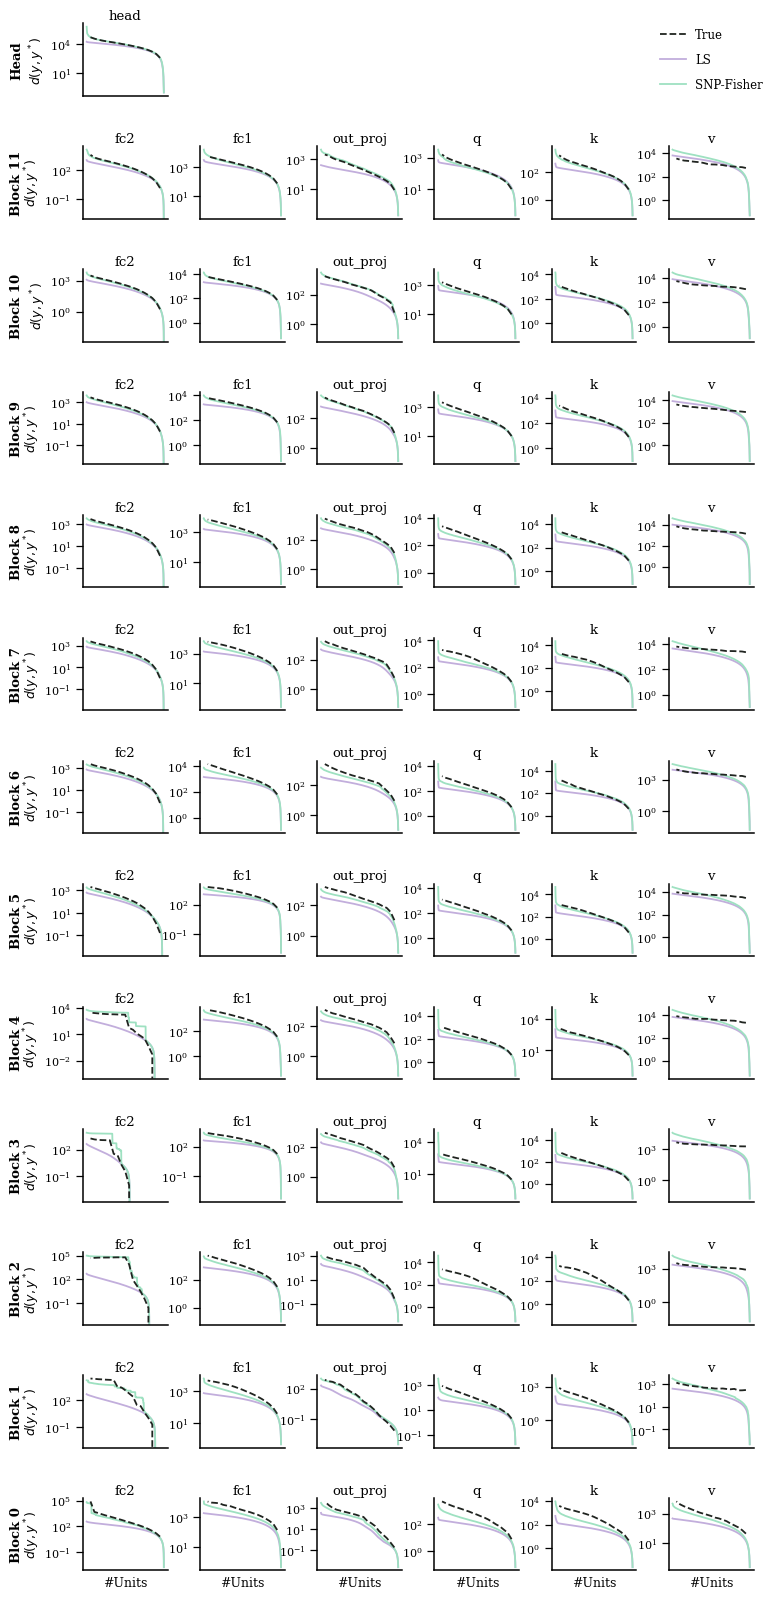

In [ ]:
STYLE = {
    "font_family": "serif",
    "base_fontsize": 9,
    "label_fontsize": 9,
    "title_fontsize": 9.5,
    "tick_fontsize": 8,
    "legend_fontsize": 8.5,
    "row_label_fontsize": 9.5,

    "measured_color": "#202420", "measured_lw": 1.3, "measured_ls": "--", "measured_label": "True",
    "local_color": "#C2AEDC",    "local_lw": 1.3,    "local_ls": "-",    "local_label": "LS",
    "calibrated_color": "#9EE1C1", "calibrated_lw": 1.3, "calibrated_ls": "-", "calibrated_label": "SNP-Fisher",

    "spine_lw": 1.1,
    "tick_width": 0.9,
    "tick_size": 5,
    "n_xticks": 4,

    "subplot_width_in": 1.30,
    "subplot_height_in": 1.40,
    "wspace": 0.38,
    "hspace": 0.70,
    "left": 0.115,
    "row_label_x": 0.03,
    "right": 0.975,
    "bottom_pad_per_row": 0.10,
    "top": 0.95,

    "dpi_png": 400,
    "out_stem": "opt125m_linear_layer_stats",
}

plt.rcParams.update({
    "font.family": STYLE["font_family"],
    "font.size": STYLE["base_fontsize"],
    "axes.labelsize": STYLE["label_fontsize"],
    "axes.titlesize": STYLE["title_fontsize"],
    "xtick.labelsize": STYLE["tick_fontsize"],
    "ytick.labelsize": STYLE["tick_fontsize"],
    "legend.fontsize": STYLE["legend_fontsize"],
    "axes.linewidth": STYLE["spine_lw"],
    "xtick.major.width": STYLE["tick_width"],
    "ytick.major.width": STYLE["tick_width"],
    "xtick.major.size": STYLE["tick_size"],
    "ytick.major.size": STYLE["tick_size"],
})


def get_block(name):
    m = re.search(r"(?:layers|h)\.(\d+)\.", name)
    return int(m.group(1)) if m else None


def is_embedding(name):
    name = name.lower()
    return any(s in name for s in ("embed_tokens", "embedding", "wte", "word_embeddings"))


def is_head(name):
    name = name.lower()
    return "lm_head" in name or name.endswith(".head") or ".head." in name


def short_name(name):
    name = name.replace("model.decoder.", "").replace("decoder.", "")
    replacements = {
        "self_attn.q_proj": "q",
        "self_attn.k_proj": "k",
        "self_attn.v_proj": "v",
        "self_attn.out_proj": "out_proj",
        "fc1": "fc1",
        "fc2": "fc2",
        "embed_tokens": "embed",
        "lm_head": "head",
    }
    for long, short in replacements.items():
        if long in name:
            return short
    return name.split(".")[-1]


def fix_qkv_order(row_records):
    slots = [i for i, r in enumerate(row_records) if short_name(r["name"]) in ("q", "k", "v")]
    qkv = sorted((row_records[i] for i in slots),
                 key=lambda r: "qkv".index(short_name(r["name"])))
    out = list(row_records)
    for i, r in zip(slots, qkv):
        out[i] = r
    return out


def _to_np(x):
    if torch.is_tensor(x):
        return x.detach().cpu().double().numpy()
    return np.asarray(x, dtype=float)


def _loss_change(evaluation):
    v = evaluation[0] if isinstance(evaluation, (tuple, list)) else evaluation
    return float(v)


def plot_layer_stats(res, block=None):
    for name, d in res.items():
        if len(d["performance"]) != len(d["units_pruned"]):
            raise ValueError(f"{name}: {len(d['performance'])} evaluations but "
                             f"{len(d['units_pruned'])} unit counts.")

    records = []
    for name, d in res.items():
        l, g = _to_np(d["local"]), _to_np(d["global"])
        n_units = len(l)
        order = np.argsort(l)
        records.append({
            "name": name,
            "lorder": np.cumsum(l[order])[::-1],
            "gorder": np.cumsum(g[order])[::-1],
            "r": n_units - np.asarray(d["units_pruned"]),
            "p": np.array([_loss_change(e) for e in d["performance"]]),
        })

    blocks, embed, head, other = {}, [], [], []
    for rec in records:
        if is_embedding(rec["name"]):
            embed.append(rec)
        elif is_head(rec["name"]):
            head.append(rec)
        elif get_block(rec["name"]) is None:
            other.append(rec)
        else:
            blocks.setdefault(get_block(rec["name"]), []).append(rec)

    rows = []
    if embed:
        rows.append(("Embed", embed))
    rows += [(f"Block {b}", blocks[b]) for b in sorted(blocks)]
    if other:
        rows.append(("Other", other))
    if head:
        rows.append(("Head", head))

    if block is None:
        rows = rows[::-1]
    else:
        rows = [r for r in rows if r[0] == f"Block {block}"]

    rows = [(label, fix_qkv_order(recs)) for label, recs in rows]

    n_rows = len(rows)
    ncols = max(len(r[1]) for r in rows)

    legend_handles = [
        Line2D([0], [0], color=STYLE[f"{k}_color"], lw=STYLE[f"{k}_lw"],
               ls=STYLE[f"{k}_ls"], label=STYLE[f"{k}_label"])
        for k in ("measured", "local", "calibrated")
    ]

    fig, axes = plt.subplots(
        n_rows, ncols, squeeze=False,
        figsize=(STYLE["subplot_width_in"] * ncols, STYLE["subplot_height_in"] * n_rows),
    )
    fig.subplots_adjust(
        left=STYLE["left"], right=STYLE["right"],
        bottom=STYLE["bottom_pad_per_row"], top=STYLE["top"],
        wspace=STYLE["wspace"], hspace=STYLE["hspace"],
    )

    for row, (row_label, row_records) in enumerate(rows):
        for col in range(ncols):
            ax = axes[row, col]

            if col >= len(row_records):
                ax.axis("off")
                # whole-model figure: legend goes in the last cell of the Head row
                if block is None and row_label == "Head" and col == ncols - 1:
                    ax.legend(handles=legend_handles, loc="center", frameon=False,
                              fontsize=STYLE["legend_fontsize"], handlelength=2.2, labelspacing=1.0)
                continue

            rec = row_records[col]

            ax.plot(rec["r"], rec["p"], lw=STYLE["measured_lw"], ls=STYLE["measured_ls"],
                    color=STYLE["measured_color"], label=STYLE["measured_label"], zorder=3)
            ax.set_yscale("log")
            ax.plot(rec["lorder"], lw=STYLE["local_lw"], ls=STYLE["local_ls"],
                    color=STYLE["local_color"], label=STYLE["local_label"], zorder=2)
            ax.plot(rec["gorder"], lw=STYLE["calibrated_lw"], ls=STYLE["calibrated_ls"],
                    color=STYLE["calibrated_color"], label=STYLE["calibrated_label"], zorder=2)

            ax.spines["top"].set_visible(False)
            ax.spines["right"].set_visible(False)
            ax.tick_params(axis="x", bottom=False, labelbottom=False)
            ax.xaxis.set_major_locator(MaxNLocator(STYLE["n_xticks"]))
            ax.ticklabel_format(axis="x", style="plain")
            ax.tick_params(axis="both", labelsize=STYLE["tick_fontsize"])
            ax.yaxis.set_minor_locator(plt.NullLocator())

            if col == 0:
                ax.set_ylabel(r"$d(y,y^*)$", fontsize=STYLE["label_fontsize"], labelpad=2)
            if row == n_rows - 1:
                ax.set_xlabel("#Units", fontsize=STYLE["label_fontsize"])
            ax.set_title(short_name(rec["name"]), pad=3, fontsize=STYLE["title_fontsize"])

        pos0 = axes[row, 0].get_position()
        fig.text(STYLE["row_label_x"], (pos0.y0 + pos0.y1) / 2, row_label,
                 rotation=90, va="center", ha="center",
                 fontsize=STYLE["row_label_fontsize"], fontweight="bold")

    if block is not None:
        axes[0, 0].legend(handles=legend_handles, loc="lower right", frameon=False,
                          handlelength=1., labelspacing=0.3, borderaxespad=0.3,
                          fontsize=STYLE["legend_fontsize"] * 0.85)

    stem = STYLE["out_stem"] + ("whole" if block is None else "")
    plt.savefig(f"{stem}.pdf", bbox_inches="tight", pad_inches=0.02)
    plt.savefig(f"{stem}.png", dpi=STYLE["dpi_png"], bbox_inches="tight", pad_inches=0.02)
    plt.show()



plot_layer_stats(res)


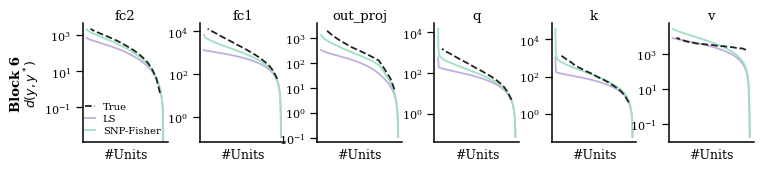

In [11]:
plot_layer_stats(res, block=6)